In [1]:
%pip install -q landingai pillow matplotlib gTTS

In [2]:
%pip install landingai

In [3]:
import io
import re
import numpy as np

from PIL import Image
from google.colab import files, userdata
from IPython.display import display, Markdown, Audio

from landingai.predict import Predictor, OcrPredictor
from landingai.visualize import overlay_bboxes
from gtts import gTTS

In [4]:
from google.colab import userdata
from landingai.predict import Predictor

API_KEY = userdata.get("LANDINGAI_API_KEY")

ENDPOINT_ID = "ec009205-6fd4-4a71-95e3-2f5e0d05e07e"

detector = Predictor(
    endpoint_id="7648ecd9-24f9-4b14-80ab-837f678adc01",
    api_key=API_KEY
)

print("Medicine Label Detection Model Connected!")

Medicine Label Detection Model Connected!


In [5]:
from landingai.predict import OcrPredictor

ocr = OcrPredictor(
    api_key=API_KEY,
    language="en"
)

print("OCR Engine Connected!")

OCR Engine Connected!


Saving med.webp to med (1).webp
Image uploaded successfully!
Image dimensions: (229, 280)


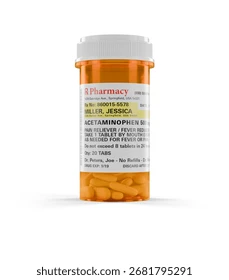

In [6]:
uploaded = files.upload()

filename = next(iter(uploaded))

with Image.open(io.BytesIO(uploaded[filename])) as img:
    image = img.convert("RGB").copy()

image_array = np.array(image)

print("Image uploaded successfully!")
print("Image dimensions:", image.size)

display(image)

In [8]:
%pip install --force-reinstall --no-cache-dir Pillow==11.3.0

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6.6/6.6 MB 21.9 MB/s  0:00:00
  Attempting uninstall: Pillow
    Found existing installation: pillow 10.4.0
    Uninstalling pillow-10.4.0:
      Successfully uninstalled pillow-10.4.0
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
landingai 0.3.49 requires pillow<11.0,>=9.0, but you have pillow 11.3.0 which is incompatible.


In [14]:
import sys
import PIL
import landingai
import numpy as np

print("Python:", sys.version)
print("Pillow:", PIL.__version__)
print("Pillow location:", PIL.__file__)
print("LandingAI:", getattr(landingai, "__version__", "Unknown"))
print("NumPy:", np.__version__)

Python: 3.13.18 (main, Oct 26 2026, 15:28:15) [GCC 13.3.0]
Pillow: 11.3.0
Pillow location: /usr/local/lib/python3.13/dist-packages/PIL/__init__.py
LandingAI: Unknown
NumPy: 1.26.4


In [15]:
%pip install --upgrade --force-reinstall --no-cache-dir Pillow landingai

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 15.8/15.8 MB 171.3 MB/s  0:00:00
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Installing backend dependencies ... done
  Preparing metadata (pyproject.toml) ... done
INFO: pip is looking at multiple versions of opencv-python to determine which version is compatible with other requirements. This could take a while.
INFO: pip is looking at multiple versions of contourpy to determine which version is compatible with other requirements. This could take a while.
INFO: pip is looking at multiple versions of opencv-python-headless to determine which version is compatible with other requirements. This could take a while.
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.0/1.0 MB 17.3 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.5/4.5 MB 325.9 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.9/1.9 MB 80.8 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 63.0/63.0 MB 213.1 MB

In [16]:
from PIL import Image
import io

test_image = Image.new("RGB", (200, 200), "white")

buffer = io.BytesIO()
test_image.save(buffer, format="JPEG")

print("Pillow image encoding successful!")

TypeError: function takes at most 16 arguments (17 given)

In [ ]:
predictions = detector.predict(image)

print("Detection Results:")

for prediction in predictions:
    print("Label:", prediction.label_name)
    print("Confidence:", prediction.score)
    print("Bounding Box:", prediction.bboxes)

In [ ]:
# Reading text
ocr_predictions = ocr.predict(image_array)

extracted_text = []

print("Extracted Medicine Label Text:\n")

for item in ocr_predictions:
    print(item.text)
    extracted_text.append(item.text)

full_text = "\n".join(extracted_text)

print("\nComplete Extracted Text:")
print(full_text)

In [ ]:
import re

def extract_medicine_information(text):

    lines = [line.strip() for line in text.split("\n") if line.strip()]

    information = {
        "Medicine Name": "Not identified",
        "Strength": "Not identified",
        "Expiry Date": "Not identified",
        "Manufacturing Date": "Not identified",
        "Batch Number": "Not identified"
    }

    for line in lines:

        upper = line.upper()

        # Extract medicine strength
        strength = re.search(
            r'\b\d+(?:\.\d+)?\s*(?:MG|MCG|G|ML|IU)\b', upper
        )

        if strength and information["Strength"] == "Not identified":
            information["Strength"] = strength.group()

        # Extract expiry date
        expiry = re.search(
            r'(?:EXP|EXPIRY|EXPIRES)\s*[:\-]?\s*(\d{1,2}[/-]\d{2,4}|\d{2}[/-]\d{2,4})',
            upper
        )

        if expiry:
            information["Expiry Date"] = expiry.group(1)

        # Extract manufacturing date
        manufacturing = re.search(
            r'(?:MFG|MFD|MANUFACTURED)\s*[:\-]?\s*(\d{1,2}[/-]\d{2,4}|\d{2}[/-]\d{2,4})',
            upper
        )

        if manufacturing:
            information["Manufacturing Date"] = manufacturing.group(1)

        # Extract batch number
        batch = re.search(
            r'(?:BATCH|B\.?NO\.?|LOT)\s*[:\-]?\s*([A-Z0-9-]+)',
            upper
        )

        if batch:
            information["Batch Number"] = batch.group(1)

    if lines:
        information["Medicine Name"] = lines[0]

    return information


medicine_info = extract_medicine_information(full_text)

for key, value in medicine_info.items():
    print(f"{key}: {value}")

In [ ]:
def medicine_assistant_response(info):

    response = f"""
# MEDICINE LABEL READING ASSISTANT

**Medicine Name:** {info['Medicine Name']}

**Strength:** {info['Strength']}

**Expiry Date:** {info['Expiry Date']}

**Manufacturing Date:** {info['Manufacturing Date']}

**Batch Number:** {info['Batch Number']}

---
Please verify all extracted information against the original medicine packaging.

This assistant reads medicine labels only.
It does not provide dosage recommendations or determine medication safety.
"""

    display(Markdown(response))

    return response


assistant_response = medicine_assistant_response(medicine_info)

In [ ]:
speech = gTTS(text=assistant_response, lang="en")

speech.save("medicine_assistant.mp3")

display(Audio("medicine_assistant.mp3", autoplay=False))

In [ ]:
import ipywidgets as widgets
from IPython.display import display, clear_output

upload_button = widgets.FileUpload(
    accept='image/*',
    multiple=False,
    description='Upload Medicine'
)

output = widgets.Output()

def process_medicine(change):
    with output:
        clear_output()

        if not upload_button.value:
            print("Please upload a medicine image.")
            return

        uploaded_file = list(upload_button.value.values())[0]
        image_bytes = uploaded_file['content']

        img = Image.open(io.BytesIO(image_bytes)).convert("RGB")
        img_array = np.array(img)

        display(img)

        # Detecting the medicine label
        predictions = detector.predict(img_array)

        # Extracting text using OCR
        ocr_predictions = ocr.predict(img_array)

        full_text = "\n".join(
            item.text for item in ocr_predictions
        )

        # Extracting medicine information
        info = extract_medicine_information(full_text)

        # Displaying the results
        display(Markdown("## Medicine Information"))

        for key, value in info.items():
            print(f"{key}: {value}")

        # Voice output
        response = medicine_assistant_response(info)

        speech = gTTS(text=response, lang="en")
        speech.save("medicine_assistant.mp3")

        display(Audio("medicine_assistant.mp3", autoplay=False))

upload_button.observe(process_medicine, names='value')

display(Markdown("# Medicine Label Reading Assistant"))
display(Markdown("Upload a medicine bottle image to extract its information."))
display(upload_button, output)